# PSR-MagPy Grid Demo

This notebook demonstrates the different grid types available in psr_magpy for creating spherical point distributions.

## Grid Types
- **SphericalGrid**: Regular grid with uniform spacing in longitude and latitude
- **HealpixGrid**: HEALPix grid for uniform spherical sampling
- **RandomGrid**: Random uniform distribution of points on a sphere
- **CustomGrid**: User-defined coordinates

## Features Demonstrated
- Grid creation and configuration
- Coordinate access and conversion
- Grid subsetting
- FITS I/O operations
- Visualization
- Performance comparison

## Setup and Imports

In [29]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Add project root to path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Import grid classes
from psr_magpy.grid.grid import (
    SphericalGrid, HealpixGrid, RandomGrid, CustomGrid, GridType
)

# Set up plotting
plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

print("✅ Setup complete!")

✅ Setup complete!


## 1. Spherical Grid

Regular grid with uniform spacing in longitude and latitude.

In [30]:
# Create spherical grid
spherical_grid = SphericalGrid(nlon=24, nlat=12, pole_lat=0.0)
print(f"SphericalGrid: {spherical_grid}")
print(f"Number of points: {spherical_grid.nline}")
print(f"Grid type: {spherical_grid.grid_type}")
print(f"Partial grid: {spherical_grid.partial}")

SphericalGrid: SphericalGrid(nlon=24, nlat=12, pole_lat=0.0 deg)
Number of points: 242
Grid type: GridType.SPHERICAL
Partial grid: False


In [31]:
# Access coordinates
print("Coordinate ranges:")
print(f"  Longitude: {spherical_grid.longitude.min():.1f}° to {spherical_grid.longitude.max():.1f}°")
print(f"  Colatitude: {spherical_grid.colatitude.min():.1f}° to {spherical_grid.colatitude.max():.1f}°")

# Show first few points
print("\nFirst 5 points:")
for i in range(min(5, spherical_grid.nline)):
    print(f"  Point {i}: lon={spherical_grid.longitude[i]:.1f}°, lat={90-spherical_grid.colatitude[i]:.1f}°")

Coordinate ranges:
  Longitude: 0.0° to 345.0°
  Colatitude: 0.0° to 180.0°

First 5 points:
  Point 0: lon=0.0°, lat=90.0°
  Point 1: lon=0.0°, lat=73.6°
  Point 2: lon=15.0°, lat=73.6°
  Point 3: lon=30.0°, lat=73.6°
  Point 4: lon=45.0°, lat=73.6°


## 2. HEALPix Grid

HEALPix grid for uniform spherical sampling.

In [32]:
# Create HEALPix grid
healpix_grid = HealpixGrid(nside=4)
print(f"HealpixGrid: {healpix_grid}")
print(f"Number of points: {healpix_grid.nline}")
print(f"NSIDE: {healpix_grid.nside}")
print(f"Resolution: {healpix_grid.nline / (12 * healpix_grid.nside**2):.2f} points per pixel")

HealpixGrid: HealpixGrid(nside=4)
Number of points: 192
NSIDE: 4
Resolution: 1.00 points per pixel


## 3. Random Grid

Random uniform distribution of points on a sphere using the Muller method.

In [33]:
# Create random grid
random_grid = RandomGrid(nline_ori=1000)
print(f"RandomGrid: {random_grid}")
print(f"Number of points: {random_grid.nline}")

# Verify uniform distribution
print("\nDistribution statistics:")
print(f"  Mean longitude: {np.mean(random_grid.longitude):.1f}°")
print(f"  Mean colatitude: {np.mean(random_grid.colatitude):.1f}°")
print(f"  Std longitude: {np.std(random_grid.longitude):.1f}°")
print(f"  Std colatitude: {np.std(random_grid.colatitude):.1f}°")

RandomGrid: RandomGrid(nline_ori=1000)
Number of points: 1000

Distribution statistics:
  Mean longitude: 180.8°
  Mean colatitude: 91.4°
  Std longitude: 103.9°
  Std colatitude: 38.7°


## 4. Custom Grid

Grid with user-defined coordinates.

In [34]:
from astropy.coordinates import CartesianRepresentation

# Create custom coordinates in a figure-8 pattern on the sphere
n_points = 200
t = np.linspace(0, 2*np.pi, n_points, endpoint=False)

# Figure-8 parametric equations on sphere
# Using Lemniscate of Bernoulli projected onto sphere
a = 1.0  # Scale factor
r = 1.0  # Sphere radius

# Parametric equations for figure-8
x = a * np.cos(t) / (1 + np.sin(t)**2)
y = a * np.sin(t) * np.cos(t) / (1 + np.sin(t)**2)

# Project onto sphere surface
# Convert to spherical coordinates
r_cyl = np.sqrt(x**2 + y**2)
z = np.sqrt(r**2 - r_cyl**2)  # Upper hemisphere

# Convert to spherical coordinates
theta = np.arccos(z/r)  # Colatitude
phi = np.arctan2(y, x)  # Longitude

# Handle negative phi values
phi[phi < 0] += 2*np.pi

# Convert to Cartesian coordinates
from astropy.coordinates import PhysicsSphericalRepresentation
from astropy import units as u

spherical = PhysicsSphericalRepresentation(
    phi=phi * u.rad,
    theta=theta * u.rad,
    r=r
)
cartesian = spherical.represent_as(CartesianRepresentation)

# Create custom grid
custom_grid = CustomGrid(nline_ori=n_points, coordinates=cartesian)
print(f"CustomGrid: {custom_grid}")
print(f"Number of points: {custom_grid.nline}")
print(f"Coordinates provided: {custom_grid.footpoint_coordinates is not None}")

CustomGrid: CustomGrid(nline_ori=200)
Number of points: 200
Coordinates provided: True


## 5. Grid Visualization

Compare different grid types visually.

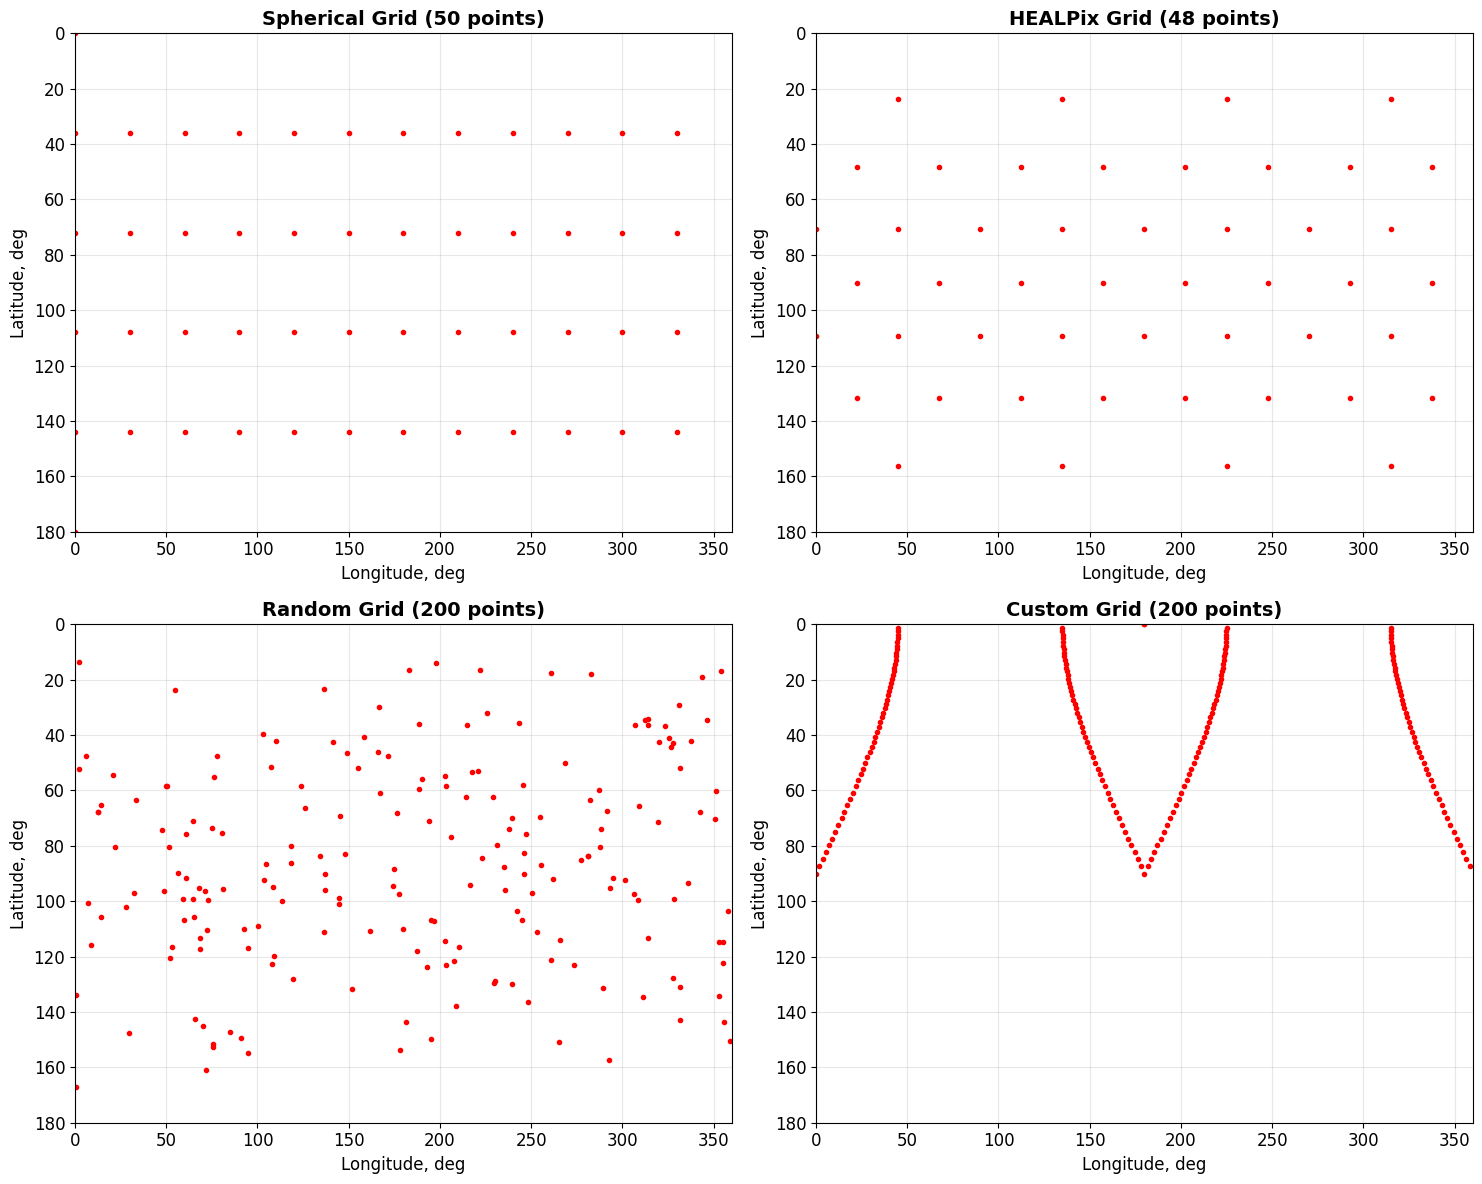

In [35]:
# Create figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

# Grids to plot
grids = [
    (SphericalGrid(12, 6), "Spherical Grid", axes[0]),
    (HealpixGrid(2), "HEALPix Grid", axes[1]),
    (RandomGrid(200), "Random Grid", axes[2]),
    (custom_grid, "Custom Grid", axes[3])
]

# Plot each grid
for grid, title, ax in grids:
    grid.plot_footpoint_coordinates(ax=ax, marker='o', markersize=3)
    ax.set_title(f"{title} ({grid.nline} points)", fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Grid Subsetting

Demonstrate how to create subsets of grids.

In [36]:
# Create a larger grid for subsetting
large_grid = RandomGrid(nline_ori=500)
print(f"Original grid: {large_grid.nline} points")

# Create subset (every 5th point)
subset_indices = np.arange(0, large_grid.nline, 5)
subset_grid = large_grid.subset_grid(subset_indices)
print(f"Subset grid: {subset_grid.nline} points")
print(f"Subset is partial: {subset_grid.partial}")
print(f"Subset indices: {subset_grid.indices[:10]}...")

Original grid: 500 points
Subset grid: 100 points
Subset is partial: True
Subset indices: [ 0  5 10 15 20 25 30 35 40 45]...


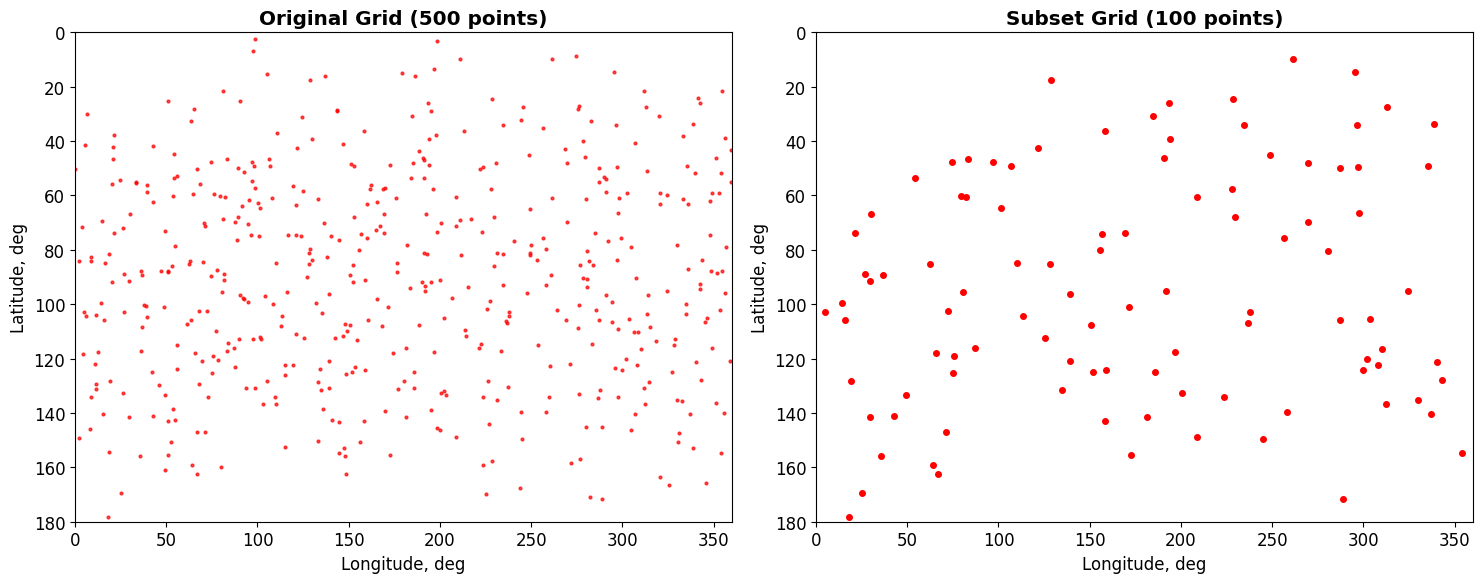

In [37]:
# Visualize subset
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Original grid
large_grid.plot_footpoint_coordinates(ax=ax1, marker='o', markersize=2, alpha=0.7)
ax1.set_title(f"Original Grid ({large_grid.nline} points)", fontweight='bold')

# Subset grid
subset_grid.plot_footpoint_coordinates(ax=ax2, marker='o', markersize=4, color='red')
ax2.set_title(f"Subset Grid ({subset_grid.nline} points)", fontweight='bold')

plt.tight_layout()
plt.show()

## 7. FITS I/O Operations

Save and load grids to/from FITS files.

In [38]:
# Create output directory
output_dir = Path("grid_output")
output_dir.mkdir(exist_ok=True)

# Save different grid types
grids_to_save = [
    (SphericalGrid(8, 4), "spherical_grid.fits"),
    (HealpixGrid(2), "healpix_grid.fits"),
    (RandomGrid(100), "random_grid.fits"),
    (custom_grid, "custom_grid.fits")
]

for grid, filename in grids_to_save:
    filepath = output_dir / filename
    grid.save_to_fits(str(filepath))
    print(f"Saved {grid.__class__.__name__} to {filepath}")

[grid.py] INFO     Saving grid to grid_output/spherical_grid.fits
[grid.py] INFO     Grid successfully saved to grid_output/spherical_grid.fits
Saved SphericalGrid to grid_output/spherical_grid.fits
[grid.py] INFO     Saving grid to grid_output/healpix_grid.fits
[grid.py] INFO     Grid successfully saved to grid_output/healpix_grid.fits
Saved HealpixGrid to grid_output/healpix_grid.fits
[grid.py] INFO     Saving grid to grid_output/random_grid.fits
[grid.py] INFO     Grid successfully saved to grid_output/random_grid.fits
Saved RandomGrid to grid_output/random_grid.fits
[grid.py] INFO     Saving grid to grid_output/custom_grid.fits
[grid.py] INFO     Grid successfully saved to grid_output/custom_grid.fits
Saved CustomGrid to grid_output/custom_grid.fits


In [39]:
# Load grids back
loaded_grids = {}

for grid, filename in grids_to_save:
    filepath = output_dir / filename
    loaded_grid = type(grid).load_from_fits(str(filepath))
    loaded_grids[filename] = loaded_grid
    print(f"Loaded {filename}: {loaded_grid.nline} points, type={loaded_grid.grid_type}")

Loaded spherical_grid.fits: 18 points, type=GridType.SPHERICAL
Loaded healpix_grid.fits: 48 points, type=GridType.HEALPIX
Loaded random_grid.fits: 100 points, type=GridType.RANDOM
Loaded custom_grid.fits: 200 points, type=GridType.CUSTOM


In [40]:
# Verify loaded grids match original
for grid, filename in grids_to_save:
    loaded = loaded_grids[filename]
    original_coords = grid.footpoint_coordinates.xyz.value
    loaded_coords = loaded.footpoint_coordinates.xyz.value
    
    diff = np.abs(original_coords - loaded_coords).max()
    print(f"{filename}: max coordinate difference = {diff:.2e}")
    
    if diff < 1e-10:
        print(f"  ✅ {filename} loaded correctly")
    else:
        print(f"  ❌ {filename} has differences")

spherical_grid.fits: max coordinate difference = 0.00e+00
  ✅ spherical_grid.fits loaded correctly
healpix_grid.fits: max coordinate difference = 0.00e+00
  ✅ healpix_grid.fits loaded correctly
random_grid.fits: max coordinate difference = 0.00e+00
  ✅ random_grid.fits loaded correctly
custom_grid.fits: max coordinate difference = 0.00e+00
  ✅ custom_grid.fits loaded correctly


## 9. Advanced Features

Demonstrate advanced grid features.

Tilted grid pole latitude: 45.0°


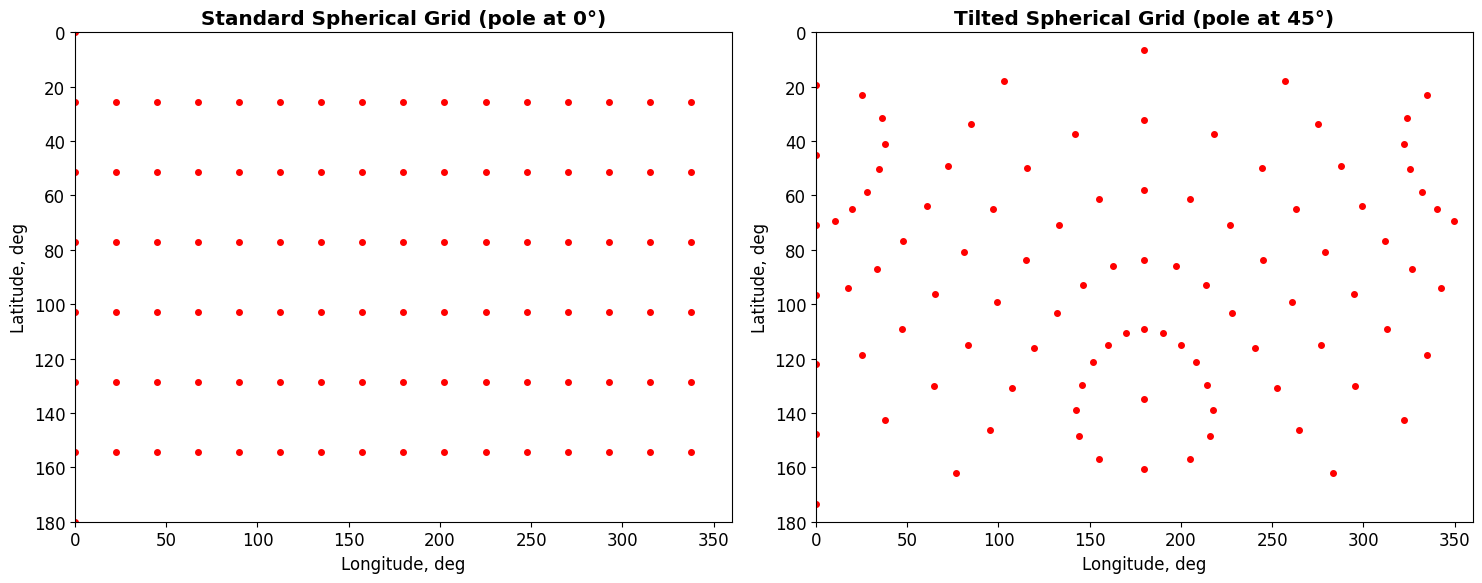

In [41]:
# Spherical grid with tilted pole
tilted_grid = SphericalGrid(nlon=16, nlat=8, pole_lat=45.0)
print(f"Tilted grid pole latitude: {tilted_grid.pole_lat.deg}°")

# Plot comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Standard grid
standard_grid = SphericalGrid(16, 8, pole_lat=0.0)
standard_grid.plot_footpoint_coordinates(ax=ax1, marker='o', markersize=4)
ax1.set_title("Standard Spherical Grid (pole at 0°)", fontweight='bold')

# Tilted grid
tilted_grid.plot_footpoint_coordinates(ax=ax2, marker='o', markersize=4, color='red')
ax2.set_title("Tilted Spherical Grid (pole at 45°)", fontweight='bold')

plt.tight_layout()
plt.show()

In [42]:
# Custom grid with set_coordinates method
empty_custom = CustomGrid(nline_ori=5)
print(f"Empty custom grid coordinates: {empty_custom.footpoint_coordinates}")

# Set coordinates later
new_coords = CartesianRepresentation(
    x=[1, 0, -1, 0, 0],
    y=[0, 1, 0, -1, 0],
    z=[0, 0, 0, 0, 1]
)
empty_custom.set_coordinates(new_coords)
print(f"Updated custom grid coordinates: {empty_custom.footpoint_coordinates}")

Empty custom grid coordinates: [(nan, nan, nan), (nan, nan, nan), (nan, nan, nan), (nan, nan, nan),
 (nan, nan, nan)] 
Updated custom grid coordinates: [( 1.,  0., 0.), ( 0.,  1., 0.), (-1.,  0., 0.), ( 0., -1., 0.),
 ( 0.,  0., 1.)] 


## 10. Summary

This demo has shown:

✅ **Grid Types**: Spherical, HEALPix, Random, and Custom grids
✅ **Features**: Creation, subsetting, FITS I/O, visualization
✅ **Performance**: Creation time and memory usage comparison
✅ **Advanced**: Tilted poles, custom coordinates, grid operations

### Key Takeaways:

1. **SphericalGrid**: Best for regular sampling, supports pole tilting
2. **HealpixGrid**: Uniform area coverage, efficient for large datasets
3. **RandomGrid**: Good for statistical sampling, simple to use
4. **CustomGrid**: Flexible for user-defined point distributions

### Next Steps:
- Explore field line tracing with these grids
- Experiment with different grid parameters
- Use grids for specific astrophysical applications